/home/arunavk/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Top 10 Re(neff): [2.68614537 2.68608726 2.68433967 2.68331376 2.68055032 2.67370039
 2.67098724 2.6670894  2.66653365 2.6642081 ]
n_clad ~ 1.444 n_core ~ 3.48

 k   neff     Gamma      <eps_r>     r_eff (µm)
 0   2.6861     0.001       2.092       3.097
 1   2.6861     0.003       2.111       3.374
 2   2.6843     0.000       2.087       3.401
 3   2.6833     0.003       2.111       3.397
 4   2.6806     0.001       2.091       3.406
 5   2.6737     0.001       2.094       3.406
 6   2.6710     0.003       2.111       3.401
 7   2.6671     0.002       2.107       3.403
 8   2.6665     0.001       2.090       3.405
 9   2.6642     0.002       2.110       3.400
10   2.6621     0.003       2.114       3.390
11   2.6618     0.003       2.111       3.395
12   2.6605     0.000       2.088       3.393
13   2.6604     0.000       2.089       3.405
14   2.6599     0.002       2.107       3.394
15   2.6586     0.001       2.093       3.406
16   2.6533     0.001       2.100       3.400
17   2.652

/tmp/ipykernel_509101/3577732516.py:336: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


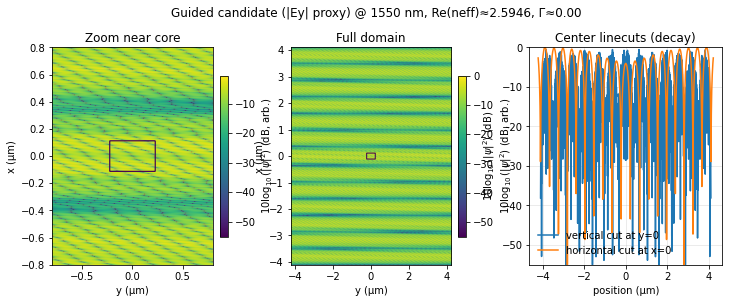

In [1]:
#!/usr/bin/env python3
"""
SOI 220×450 nm waveguide mode solver (semi-vectorial scalar Helmholtz) — corrected.

What this version fixes vs your earlier runs:
  1) Correct eigen-operator sign:
        (-∇_t^2 + k0^2 eps_r) ψ = β^2 ψ
  2) Uses shift–invert around a physically reasonable target neff (avoids grid/Laplacian modes).
  3) Robust mode selection using a combined score:
        - core confinement Γ
        - eps-weighted overlap <eps_r> (rejects cladding/box-like modes)
        - localization radius r_eff (rejects domain-wide oscillatory modes)
  4) “Confinement-proof” visualization:
        - zoom near core (dB)
        - full domain (dB)
        - center linecuts (dB)

Dependencies: numpy, scipy, matplotlib
"""

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt


# --------------------------
# Materials (simple dispersion)
# --------------------------
def n_Si(lambda_um: float) -> float:
    # Mild dispersion: ~3.50 at 1.31 µm, ~3.48 at 1.55 µm
    lam = lambda_um
    return 3.50 + (3.48 - 3.50) * (lam - 1.31) / (1.55 - 1.31)


def n_SiO2(lambda_um: float) -> float:
    # Mild dispersion: ~1.445 at 1.31 µm, ~1.444 at 1.55 µm
    lam = lambda_um
    return 1.445 + (1.444 - 1.445) * (lam - 1.31) / (1.55 - 1.31)


# --------------------------
# Grid + geometry
# --------------------------
def make_grid(
    dx_nm: float = 5.0,     # <-- finer grid helps a lot for high index contrast
    pad_um: float = 4.0,    # <-- larger padding reduces box-mode influence
    core_w_nm: float = 450.0,
    core_t_nm: float = 220.0,
):
    """
    x: vertical (thickness direction)
    y: horizontal (width direction)
    Returns x,y (m), dx (m), core_w, core_t (m)
    """
    dx = dx_nm * 1e-9
    pad = pad_um * 1e-6
    core_w = core_w_nm * 1e-9
    core_t = core_t_nm * 1e-9

    Lx = core_t + 2 * pad
    Ly = core_w + 2 * pad

    Nx = int(np.round(Lx / dx)) + 1
    Ny = int(np.round(Ly / dx)) + 1

    x = (np.arange(Nx) - (Nx - 1) / 2) * dx
    y = (np.arange(Ny) - (Ny - 1) / 2) * dx
    return x, y, dx, core_w, core_t


def eps_r_map(x, y, lambda_um, core_w_m, core_t_m):
    """
    Relative permittivity eps_r(x,y)=n^2.
    Si core (220×450 nm) embedded in SiO2 on all sides.
    """
    n_core = n_Si(lambda_um)
    n_clad = n_SiO2(lambda_um)

    eps = (n_clad**2) * np.ones((x.size, y.size), dtype=float)

    X, Y = np.meshgrid(x, y, indexing="ij")
    core = (np.abs(X) <= core_t_m / 2) & (np.abs(Y) <= core_w_m / 2)
    eps[core] = n_core**2
    return eps


def core_mask(x, y, core_w_m, core_t_m):
    X, Y = np.meshgrid(x, y, indexing="ij")
    return (np.abs(X) <= core_t_m / 2) & (np.abs(Y) <= core_w_m / 2)


# --------------------------
# Absorbing buffer (simple)
# --------------------------
def damping_profile(N: int, n_pml: int, strength: float = 3.0) -> np.ndarray:
    g = np.zeros(N, dtype=float)
    for i in range(n_pml):
        s = (n_pml - i) / n_pml
        g[i] = strength * (s**2)
        g[N - 1 - i] = strength * (s**2)
    return g


def build_helmholtz_operator(
    eps_r: np.ndarray,
    k0: float,
    dx: float,
    n_pml: int = 30,
    pml_strength: float = 3.0,
    loss_scale: float = 5e-3
):
    """
    Correct scalar eigenproblem:
        (-∇_t^2 + k0^2 eps_r) ψ = β^2 ψ
    Adds a weak lossy buffer near edges to suppress reflections / box artifacts.
    """
    Nx, Ny = eps_r.shape
    N = Nx * Ny

    ex = np.ones(Nx)
    ey = np.ones(Ny)

    D2x = sp.diags([ex, -2 * ex, ex], offsets=[-1, 0, 1], shape=(Nx, Nx)) / (dx**2)
    D2y = sp.diags([ey, -2 * ey, ey], offsets=[-1, 0, 1], shape=(Ny, Ny)) / (dx**2)

    Ix = sp.eye(Nx, format="csr")
    Iy = sp.eye(Ny, format="csr")

    Lap = sp.kron(Iy, D2x, format="csr") + sp.kron(D2y, Ix, format="csr")  # ∇_t^2

    gx = damping_profile(Nx, n_pml, pml_strength)
    gy = damping_profile(Ny, n_pml, pml_strength)
    Gx, Gy = np.meshgrid(gx, gy, indexing="ij")
    eta = Gx + Gy

    eps_c = eps_r * (1.0 - 1j * loss_scale * eta)
    V = sp.diags((k0**2) * eps_c.reshape(-1), 0, shape=(N, N), format="csr")

    # IMPORTANT SIGN:
    A = (-Lap) + V
    return A


# --------------------------
# Mode solve: shift–invert around target neff
# --------------------------
def solve_modes_shiftinvert(
    eps_r,
    lambda_um,
    dx,
    nmodes=60,
    target_neff=2.6
):
    """
    Solve (-∇_t^2 + k0^2 eps_r) ψ = β^2 ψ
    using shift–invert near β^2=(k0*target_neff)^2.
    """
    lam = lambda_um * 1e-6
    k0 = 2 * np.pi / lam

    A = build_helmholtz_operator(eps_r, k0, dx)

    sigma = (k0 * target_neff) ** 2

    vals, vecs = spla.eigs(A, k=nmodes, sigma=sigma, which="LM")

    betas = np.sqrt(vals)
    # pick branch with positive real part when possible
    betas = np.where(np.real(betas) < 0, -betas, betas)

    neff = betas / k0

    # Sort by decreasing Re(neff)
    order = np.argsort(-np.real(neff))
    betas = betas[order]
    neff = neff[order]
    vecs = vecs[:, order]

    Nx, Ny = eps_r.shape
    modes = vecs.reshape(Nx, Ny, nmodes)
    return betas, neff, modes


# --------------------------
# Mode diagnostics + robust selection
# --------------------------
def compute_mode_metrics(x, y, eps_r, neff, modes, core_w_m, core_t_m):
    """
    For each mode compute:
      - core confinement Γ = ∫core |ψ|^2 / ∫all |ψ|^2
      - eps-weighted average <eps_r> = ∫ eps_r |ψ|^2 / ∫ |ψ|^2
      - localization radius r_eff from 2nd moment
    """
    X, Y = np.meshgrid(x, y, indexing="ij")
    cmask = (np.abs(X) <= core_t_m/2) & (np.abs(Y) <= core_w_m/2)

    dx = float(np.abs(x[1] - x[0]))
    dy = float(np.abs(y[1] - y[0]))
    dA = dx * dy

    r2 = X**2 + Y**2

    metrics = []
    for k in range(neff.size):
        psi = modes[:, :, k]
        I = np.abs(psi) ** 2

        Itot = (I.sum() + 1e-30) * dA
        Icore = I[cmask].sum() * dA

        gamma = Icore / Itot
        eps_avg = (eps_r * I).sum() * dA / Itot
        r_eff = np.sqrt((r2 * I).sum() * dA / Itot)

        metrics.append({
            "k": k,
            "neff": float(np.real(neff[k])),
            "gamma": float(gamma),
            "eps_avg": float(eps_avg),
            "r_eff": float(r_eff),
        })
    return metrics


def pick_best_guided_mode(metrics, n_clad, n_core, min_gamma=0.05):
    """
    Choose best guided candidate using a combined score:
      score ∝ eps_avg * (gamma + small) / r_eff
    """
    candidates = []
    for m in metrics:
        ne = m["neff"]
        if not (n_clad < ne < n_core):
            continue
        score = m["eps_avg"] * (m["gamma"] + 1e-3) / (m["r_eff"] + 1e-12)
        candidates.append((score, m))

    if not candidates:
        raise RuntimeError("No guided candidates found in (n_clad, n_core). Increase nmodes or adjust target_neff.")

    candidates.sort(key=lambda t: t[0], reverse=True)
    best = candidates[0][1]

    if best["gamma"] < min_gamma:
        print("Warning: best candidate still has low core confinement Γ.")
        print("Try: smaller dx_nm, larger pad_um, nmodes=100, or adjust target_neff (2.2–2.9).")

    return best, candidates


# --------------------------
# Confinement-proof plotting
# --------------------------
def normalize_field(F):
    m = np.max(np.abs(F))
    return F / m if m > 0 else F


def plot_mode_confinement(
    x, y, eps_r,
    field,
    core_w_m, core_t_m,
    title="",
    zoom_um=0.8,
    floor_db=-55
):
    """
    Show confinement clearly: zoom + full domain + center linecuts (dB).
    """
    x_um = x * 1e6
    y_um = y * 1e6

    F = normalize_field(field)
    I = np.abs(F) ** 2
    IdB = 10 * np.log10(I + 1e-30)
    IdB = np.maximum(IdB, floor_db)

    cmask = core_mask(x, y, core_w_m, core_t_m)

    ix = np.where((x_um >= -zoom_um) & (x_um <= zoom_um))[0]
    iy = np.where((y_um >= -zoom_um) & (y_um <= zoom_um))[0]

    ix0 = np.argmin(np.abs(x_um))
    iy0 = np.argmin(np.abs(y_um))

    line_x = 10 * np.log10(I[:, iy0] + 1e-30)
    line_y = 10 * np.log10(I[ix0, :] + 1e-30)

    fig = plt.figure(figsize=(12, 4.0))
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.1], wspace=0.35)

    # Zoom
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(
        IdB[np.ix_(ix, iy)],
        extent=[y_um[iy[0]], y_um[iy[-1]], x_um[ix[0]], x_um[ix[-1]]],
        origin="lower",
        aspect="auto",
    )
    ax1.contour(y_um[iy], x_um[ix], cmask[np.ix_(ix, iy)].astype(float), levels=[0.5], linewidths=1.2)
    ax1.set_title("Zoom near core")
    ax1.set_xlabel("y (µm)")
    ax1.set_ylabel("x (µm)")
    cb1 = plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
    cb1.set_label(r"$10\log_{10}(|\psi|^2)$ (dB, arb.)")

    # Full domain
    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(
        IdB,
        extent=[y_um.min(), y_um.max(), x_um.min(), x_um.max()],
        origin="lower",
        aspect="auto",
    )
    ax2.contour(y_um, x_um, cmask.astype(float), levels=[0.5], linewidths=1.0)
    ax2.set_title("Full domain")
    ax2.set_xlabel("y (µm)")
    ax2.set_ylabel("x (µm)")
    cb2 = plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
    cb2.set_label(r"$10\log_{10}(|\psi|^2)$ (dB, arb.)")

    # Linecuts
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.plot(x_um, np.maximum(line_x, floor_db), label="vertical cut at y=0")
    ax3.plot(y_um, np.maximum(line_y, floor_db), label="horizontal cut at x=0")
    ax3.axhline(floor_db, linestyle="--", linewidth=1)
    ax3.set_ylim([floor_db, 0])
    ax3.set_xlabel("position (µm)")
    ax3.set_ylabel(r"$10\log_{10}(|\psi|^2)$ (dB)")
    ax3.set_title("Center linecuts (decay)")
    ax3.grid(True, alpha=0.3)
    ax3.legend(loc="lower left", frameon=False)

    fig.suptitle(title, y=1.02, fontsize=12)
    plt.tight_layout()
    plt.show()


# --------------------------
# Example run: TE-like fundamental at 1550 nm + print mode table
# --------------------------
def run_one_wavelength(lam_um=1.55, target_neff=2.6):
    x, y, dx, core_w, core_t = make_grid(
        dx_nm=5.0,
        pad_um=4.0,
        core_w_nm=450.0,
        core_t_nm=220.0,
    )

    eps = eps_r_map(x, y, lam_um, core_w, core_t)

    betas, neff, modes = solve_modes_shiftinvert(
        eps, lam_um, dx, nmodes=80, target_neff=target_neff
    )

    nclad = n_SiO2(lam_um)
    ncore = n_Si(lam_um)

    print("Top 10 Re(neff):", np.real(neff[:10]))
    print("n_clad ~", nclad, "n_core ~", ncore)

    metrics = compute_mode_metrics(x, y, eps, neff, modes, core_w, core_t)

    # Print a compact table for the first 20 modes in this ordering
    print("\n k   neff     Gamma      <eps_r>     r_eff (µm)")
    for m in metrics[:20]:
        print(f"{m['k']:2d}  {m['neff']:7.4f}  {m['gamma']:8.3f}   {m['eps_avg']:9.3f}   {m['r_eff']*1e6:9.3f}")

    best, ranked = pick_best_guided_mode(metrics, nclad, ncore, min_gamma=0.05)

    print("\nSelected guided candidate:")
    print("k =", best["k"], "Re(neff) =", best["neff"], "Gamma =", best["gamma"],
          "<eps_r> =", best["eps_avg"], "r_eff (µm) =", best["r_eff"]*1e6)

    psi_best = modes[:, :, best["k"]]

    plot_mode_confinement(
        x, y, eps,
        field=psi_best,
        core_w_m=core_w, core_t_m=core_t,
        title=f"Guided candidate (|Ey| proxy) @ {int(lam_um*1000)} nm, Re(neff)≈{best['neff']:.4f}, Γ≈{best['gamma']:.2f}",
        zoom_um=0.8,
        floor_db=-55
    )

    return x, y, eps, neff, modes, best


if __name__ == "__main__":
    # Run at 1550 nm. If selection still looks odd, try target_neff=2.2 or 2.8.
    run_one_wavelength(lam_um=1.55, target_neff=2.6)


In [2]:
# if __name__ == "__main__":
#     # Run at 1550 nm. If selection still looks odd, try target_neff=2.2 or 2.8.
#     run_one_wavelength(lam_um=1.55, target_neff=2.8)
